In [1]:
# Importing required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [5]:
# Inspecting the uploaded CSV file

file_path = '/content/diabetes.csv'

with open(file_path, 'r', encoding='utf-8-sig') as file:
    for i in range(10):
        line = file.readline()
        print(f"Line {i+1}: {repr(line)}")

Line 1: '<!DOCTYPE html>\n'
Line 2: '<html lang="en"><head>\n'
Line 3: '<meta http-equiv="content-type" content="text/html; charset=UTF-8">\n'
Line 4: '  <title>pima-indians-diabetes.csv</title>\n'
Line 5: '  <meta charset="utf-8">\n'
Line 6: '    <meta name="robots" content="index, follow">\n'
Line 7: '  <meta name="description" content="Discover what actually works in AI. Join millions of builders, researchers, and labs evaluating agents, models, and frontier technology through crowdsourced benchmarks, competitions, and hackathons.">\n'
Line 8: '    <meta name="viewport" content="width=device-width, initial-scale=1.0, maximum-scale=5.0, minimum-scale=1.0">\n'
Line 9: '  <meta name="theme-color" content="#008ABC">\n'
Line 10: '  <script src="diabetes_files/cb=gapi.es" nonce="" async=""></script><script type="text/javascript" async="" charset="utf-8" src="diabetes_files/recaptcha__en.js" crossorigin="anonymous" integrity="sha384-Zx8ijUQvi289DhK2tX/VDWxlUZSZu+HvV2ONyCK8kej9PeTMflozlh2lT

In [6]:
import pandas as pd

# Column names
columns = [
    'Pregnancies',
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI',
    'DiabetesPedigreeFunction',
    'Age',
    'Outcome'
]

# Directly loading the original dataset
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

df = pd.read_csv(url, names=columns)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [7]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [8]:
print("Dataset_Dimensions:",df.shape)

Dataset_Dimensions: (768, 9)


In [9]:
df.to_csv('/content/diabetes_clean.csv', index=False)

print("Clean dataset saved successfully!")

Clean dataset saved successfully!


In [10]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 768
Number of columns: 9


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [12]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [13]:
print(df['Outcome'].value_counts())

Outcome
0    500
1    268
Name: count, dtype: int64


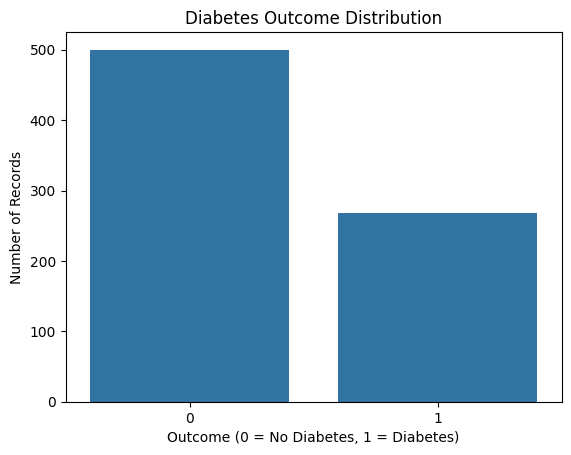

In [14]:
sns.countplot(x='Outcome', data=df)

plt.title('Diabetes Outcome Distribution')
plt.xlabel('Outcome (0 = No Diabetes, 1 = Diabetes)')
plt.ylabel('Number of Records')
plt.show()

In [15]:
# Checking zero values in each column

zero_counts = (df == 0).sum()

print("Zero values in each column:")
print(zero_counts)

Zero values in each column:
Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64


In [16]:
# Creating a copy of the original dataset

df_clean = df.copy()

print("Original dataset preserved!")
print("Clean dataset copy created!")

Original dataset preserved!
Clean dataset copy created!


In [17]:
# Clinical features where zero represents missing data

clinical_features = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

# Count zero values before cleaning

print("Zero values before preprocessing:")

for column in clinical_features:
    print(column, ":", (df_clean[column] == 0).sum())

Zero values before preprocessing:
Glucose : 5
BloodPressure : 35
SkinThickness : 227
Insulin : 374
BMI : 11


In [18]:
# Replacing invalid zeros with NaN

import numpy as np

df_clean[clinical_features] = df_clean[clinical_features].replace(0, np.nan)

print("Invalid zero values replaced with NaN!")

Invalid zero values replaced with NaN!


In [23]:
print("Zero values in Pregnancies:",
      (df_clean['Pregnancies'] == 0).sum())

Zero values in Pregnancies: 111


In [25]:
# Checking missing values

print("Missing values after replacing zeros:")

print(df_clean.isnull().sum())

Missing values after replacing zeros:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [26]:
# Imputing missing values using median

for column in clinical_features:
    median_value = df_clean[column].median()

    df_clean[column] = df_clean[column].fillna(median_value)

    print(column, "median:", median_value)

print("\nMissing values imputed successfully!")

Glucose median: 117.0
BloodPressure median: 72.0
SkinThickness median: 29.0
Insulin median: 125.0
BMI median: 32.3

Missing values imputed successfully!


In [27]:
# Checking missing values after imputation

print("Missing values after preprocessing:")

print(df_clean.isnull().sum())

Missing values after preprocessing:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [28]:
print("Cleaned dataset dimensions:", df_clean.shape)

df_clean.head()

Cleaned dataset dimensions: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,125.0,33.6,0.627,50,1
1,1,85.0,66.0,29.0,125.0,26.6,0.351,31,0
2,8,183.0,64.0,29.0,125.0,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


In [29]:
print("Missing values after preprocessing:")
print(df_clean.isnull().sum())

Missing values after preprocessing:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [30]:
# Separating patients based on diabetes outcome

non_diabetic = df_clean[df_clean['Outcome'] == 0]

diabetic = df_clean[df_clean['Outcome'] == 1]

print("Non-diabetic patients:", len(non_diabetic))
print("Diabetic patients:", len(diabetic))

Non-diabetic patients: 500
Diabetic patients: 268


In [31]:
print("Average glucose levels:")

print("Non-diabetic:",
      non_diabetic['Glucose'].mean())

print("Diabetic:",
      diabetic['Glucose'].mean())

Average glucose levels:
Non-diabetic: 110.682
Diabetic: 142.13059701492537


In [32]:
print("Average BMI:")

print("Non-diabetic:",
      non_diabetic['BMI'].mean())

print("Diabetic:",
      diabetic['BMI'].mean())

Average BMI:
Non-diabetic: 30.885600000000004
Diabetic: 35.383582089552235


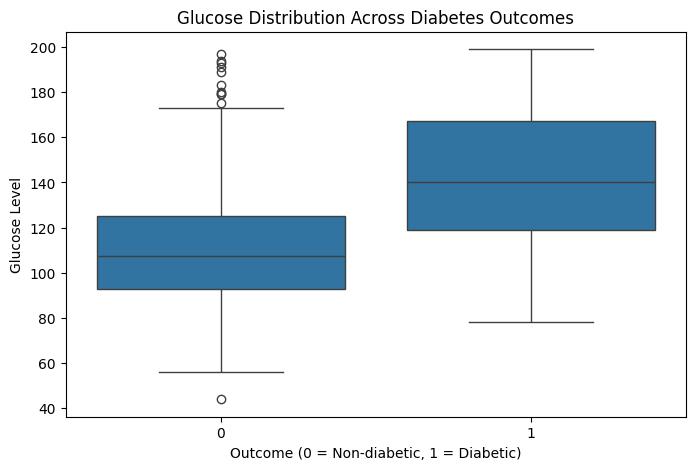

In [33]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='Outcome',
    y='Glucose',
    data=df_clean
)

plt.title('Glucose Distribution Across Diabetes Outcomes')
plt.xlabel('Outcome (0 = Non-diabetic, 1 = Diabetic)')
plt.ylabel('Glucose Level')

plt.show()

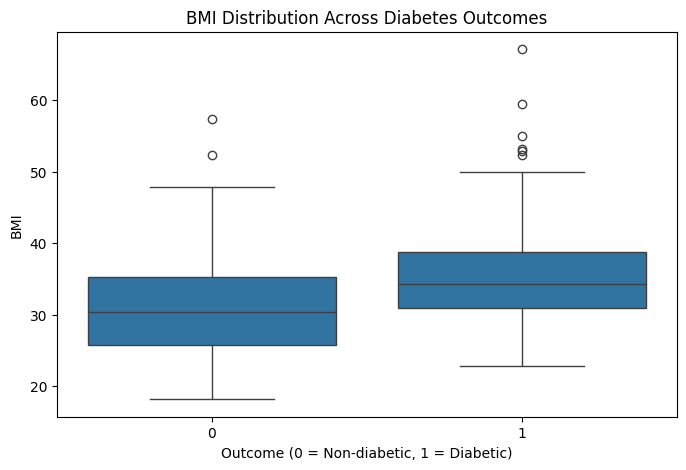

In [34]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='Outcome',
    y='BMI',
    data=df_clean
)

plt.title('BMI Distribution Across Diabetes Outcomes')
plt.xlabel('Outcome (0 = Non-diabetic, 1 = Diabetic)')
plt.ylabel('BMI')

plt.show()

In [35]:
glucose_ttest = stats.ttest_ind(
    diabetic['Glucose'],
    non_diabetic['Glucose'],
    equal_var=False
)

print("GLUCOSE T-TEST")
print("T-statistic:", glucose_ttest.statistic)
print("P-value:", glucose_ttest.pvalue)

GLUCOSE T-TEST
T-statistic: 14.852653441079662
P-value: 3.5421485614431447e-41


In [36]:
bmi_ttest = stats.ttest_ind(
    diabetic['BMI'],
    non_diabetic['BMI'],
    equal_var=False
)

print("BMI T-TEST")
print("T-statistic:", bmi_ttest.statistic)
print("P-value:", bmi_ttest.pvalue)

BMI T-TEST
T-statistic: 9.051746949833985
P-value: 2.552895685742694e-18


In [37]:
# Separating input features and target variable

X = df[[
    'Pregnancies',
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI',
    'DiabetesPedigreeFunction',
    'Age'
]]

y = df['Outcome']

print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

Input features shape: (768, 8)
Target variable shape: (768,)


In [38]:
from sklearn.model_selection import train_test_split

# Replacing invalid zeros with missing values
X = X.copy()

X[clinical_features] = X[clinical_features].replace(0, np.nan)

# Splitting the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 614
Testing records: 154


In [39]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Creating Logistic Regression pipeline

logistic_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=1000))
])

# Training the model

logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [40]:
from sklearn.naive_bayes import GaussianNB

# Creating Naive Bayes pipeline

naive_bayes_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', GaussianNB())
])

# Training the model

naive_bayes_model.fit(X_train, y_train)

print("Naive Bayes model trained successfully!")

Naive Bayes model trained successfully!


In [41]:
# Logistic Regression predictions

lr_predictions = logistic_model.predict(X_test)

# Naive Bayes predictions

nb_predictions = naive_bayes_model.predict(X_test)

print("Both models generated predictions successfully!")

Both models generated predictions successfully!


In [42]:
from sklearn.metrics import accuracy_score, classification_report

# Logistic Regression evaluation

print("LOGISTIC REGRESSION RESULTS")

print("Accuracy:",
      accuracy_score(y_test, lr_predictions))

print(classification_report(y_test, lr_predictions))


# Naive Bayes evaluation

print("NAIVE BAYES RESULTS")

print("Accuracy:",
      accuracy_score(y_test, nb_predictions))

print(classification_report(y_test, nb_predictions))

LOGISTIC REGRESSION RESULTS
Accuracy: 0.7077922077922078
              precision    recall  f1-score   support

           0       0.75      0.82      0.78       100
           1       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154

NAIVE BAYES RESULTS
Accuracy: 0.7012987012987013
              precision    recall  f1-score   support

           0       0.79      0.74      0.76       100
           1       0.57      0.63      0.60        54

    accuracy                           0.70       154
   macro avg       0.68      0.68      0.68       154
weighted avg       0.71      0.70      0.70       154



In [43]:
comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Naive Bayes'],

    'Accuracy': [
        accuracy_score(y_test, lr_predictions),
        accuracy_score(y_test, nb_predictions)
    ]
})

print(comparison)

                 Model  Accuracy
0  Logistic Regression  0.707792
1          Naive Bayes  0.701299


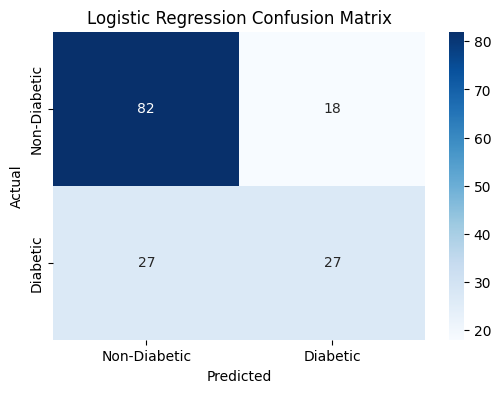

In [44]:
from sklearn.metrics import confusion_matrix

# Logistic Regression Confusion Matrix

cm_lr = confusion_matrix(y_test, lr_predictions)

plt.figure(figsize=(6,4))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non-Diabetic', 'Diabetic'],
    yticklabels=['Non-Diabetic', 'Diabetic']
)

plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

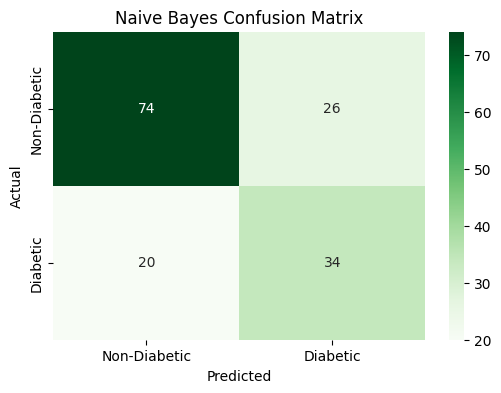

In [45]:
# Naive Bayes Confusion Matrix

cm_nb = confusion_matrix(y_test, nb_predictions)

plt.figure(figsize=(6,4))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Non-Diabetic', 'Diabetic'],
    yticklabels=['Non-Diabetic', 'Diabetic']
)

plt.title('Naive Bayes Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

In [46]:
!pip install gradio

In [47]:
import gradio as gr
import pandas as pd

# Prediction function
def predict_diabetes(
    pregnancies,
    glucose,
    blood_pressure,
    skin_thickness,
    insulin,
    bmi,
    diabetes_pedigree,
    age
):

    # Collect patient information
    patient = pd.DataFrame([{
        'Pregnancies': pregnancies,
        'Glucose': glucose,
        'BloodPressure': blood_pressure,
        'SkinThickness': skin_thickness,
        'Insulin': insulin,
        'BMI': bmi,
        'DiabetesPedigreeFunction': diabetes_pedigree,
        'Age': age
    }])

    # Logistic Regression prediction
    lr_prediction = logistic_model.predict(patient)[0]
    lr_probability = logistic_model.predict_proba(patient)[0][1]

    # Naive Bayes prediction
    nb_prediction = naive_bayes_model.predict(patient)[0]
    nb_probability = naive_bayes_model.predict_proba(patient)[0][1]

    # Prepare results
    lr_result = "Diabetes predicted" if lr_prediction == 1 else "No diabetes predicted"
    nb_result = "Diabetes predicted" if nb_prediction == 1 else "No diabetes predicted"

    result = f"""
    DIABETES RISK SCREENING RESULTS

    Logistic Regression:
    Prediction: {lr_result}
    Estimated probability: {lr_probability:.2%}

    Naive Bayes:
    Prediction: {nb_result}
    Estimated probability: {nb_probability:.2%}

    NOTE:
    These are educational model predictions,
    not medical diagnoses.
    Please consult a qualified healthcare professional
    for medical assessment.
    """

    return result


# Creating the application interface
app = gr.Interface(
    fn=predict_diabetes,

    inputs=[
        gr.Number(label="Number of Pregnancies", value=1),
        gr.Number(label="Glucose Level", value=120),
        gr.Number(label="Blood Pressure", value=70),
        gr.Number(label="Skin Thickness", value=20),
        gr.Number(label="Insulin Level", value=80),
        gr.Number(label="BMI", value=25),
        gr.Number(label="Diabetes Pedigree Function", value=0.5),
        gr.Number(label="Age", value=30)
    ],

    outputs=gr.Textbox(
        label="Diabetes Screening Results",
        lines=12
    ),

    title="Diabetes Risk Screening & Clinical Analytics App",

    description="Enter clinical measurements to obtain predictions from Logistic Regression and Naive Bayes models."
)

app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8ad1a07279d84427dd.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
